DSA 1080 Groupwork

In [1]:
#Importing pandas
import pandas as pd

#Loading the dataset
raw1 = pd.read_csv("raw(2023-2024).csv")
raw2 = pd.read_csv("raw(2024-2025).csv")

C:\Users\mwasi\AppData\Local\Temp\ipykernel_12292\3090617851.py:6: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  raw2 = pd.read_csv("raw(2024-2025).csv")


Raw 1

In [2]:
#Proving data contains 15,000 rows and 10 columns
print("Dataset Shape (Rows, Columns):")
print(raw1.shape)
print("\n" + "="*50 + "\n")

#Showing all column names in the datset
print('Dataset columns =')
print(raw1.columns)
print("\n" + "="*50 + "\n")

#Displaying the first few rows
print('First five columns:')
print(raw1.head())

Dataset Shape (Rows, Columns):
(23218, 174)


Dataset columns =
Index(['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10',
       ...
       'Q40g', 'Q40h', 'Q40i', 'Q40j', 'Q40k', 'Q40l', 'Q40m', 'Q40n', 'Q40o',
       'source'],
      dtype='object', length=174)


First five columns:
            Q1   Q2     Q3           Q4  \
0  Afghanistan  2.0   27.0  Afghanistan   
1  Afghanistan  4.0  100.0  Afghanistan   
2  Afghanistan  1.0   21.0      Albania   
3  Afghanistan  1.0   18.0      Ecuador   
4  Afghanistan  2.0   26.0        Spain   

                                                  Q5   Q6   Q7   Q8   Q9  Q10  \
0                                     القدس المفتوحة  1.0  1.0  1.0  1.0  1.0   
1                                                456  2.0  2.0  3.0  2.0  4.0   
2                                               منيا  1.0  1.0  1.0  1.0  1.0   
3  Universidad Indoamerica., Facultad Arquitectur...  2.0  1.0  1.0  1.0  4.0   
4                                De vigo

Raw 2

In [3]:
#Proving data contains 15,000 rows and 10 columns
print("Dataset Shape (Rows, Columns):")
print(raw2.shape)
print("\n" + "="*50 + "\n")

#Showing all column names in the datset
print('Dataset columns =')
print(raw2.columns)
print("\n" + "="*50 + "\n")

#Displaying the first few rows
print('First five columns:')
print(raw2.head())

Dataset Shape (Rows, Columns):
(22963, 180)


Dataset columns =
Index(['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10',
       ...
       'Q40g', 'Q40h', 'Q40i', 'Q40j', 'Q40k', 'Q40l', 'Q40m', 'Q40n', 'Q40o',
       'source'],
      dtype='object', length=180)


First five columns:
            Q1   Q2     Q3                 Q4                            Q5  \
0  Afghanistan  2.0   19.0        Afghanistan                       f\'h\'h   
1  Afghanistan  3.0  100.0        Afghanistan                            No   
2  Afghanistan  1.0   19.0             Angola                     Alastqlql   
3  Afghanistan  4.0   95.0  Antigua & Barbuda       Facultad de gastronomía   
4  Afghanistan  3.0   22.0     Czech Republic  Economics and management CZU   

    Q6   Q7   Q8   Q9  Q10  ...  Q40g  Q40h  Q40i  Q40j  Q40k  Q40l  Q40m  \
0  2.0  1.0  2.0  2.0  2.0  ...   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
1  1.0  1.0  3.0  1.0  3.0  ...   NaN   NaN   NaN   NaN   NaN   NaN   NaN  

Initial observation

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

1.Number of respondents who used ChatGPT increased

2023-24    71.4%
2024-25    91.1%
dtype: object


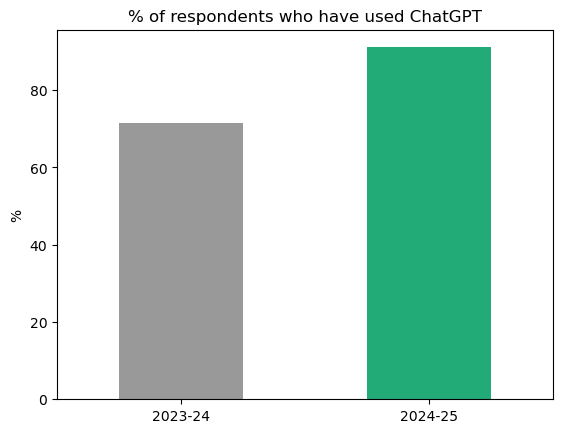

In [ ]:
#Number of respondents who used ChatGPT increased
raw1['used'] = raw1['Q13'].map({1: 1, 2: 0})     # 2023-24: single Yes/No
raw2['used'] = raw2['Q13a']                        # 2024-25: multi-select, Q13a = ChatGPT ticked
adopt = pd.Series({'2023-24': raw1['used'].mean(), '2024-25': raw2['used'].mean()}) * 100
print(adopt.round(1).astype(str) + '%')
adopt.plot.bar(color=['#999', '#2a7'], rot=0, title='% of respondents who have used ChatGPT'); plt.ylabel('%'); plt.show()

2. Most respondents had positive emotions while negative ones were rarer, across both periods

            2023-24  2024-25
Sad            1.73     1.82
Ashamed        1.82     1.87
Angry          1.90     2.02
Anxious        2.06     2.14
Frustrated     2.20     2.30
Bored          2.26     2.31
Confused       2.54     2.61
Proud          2.54     2.61
Surprised      2.85     2.81
Excited        2.92     2.92
Relieved       2.98     3.08
Hopeful        3.09     3.15
Happy          3.12     3.18
Calm           3.27     3.34
Curious        3.43     3.39


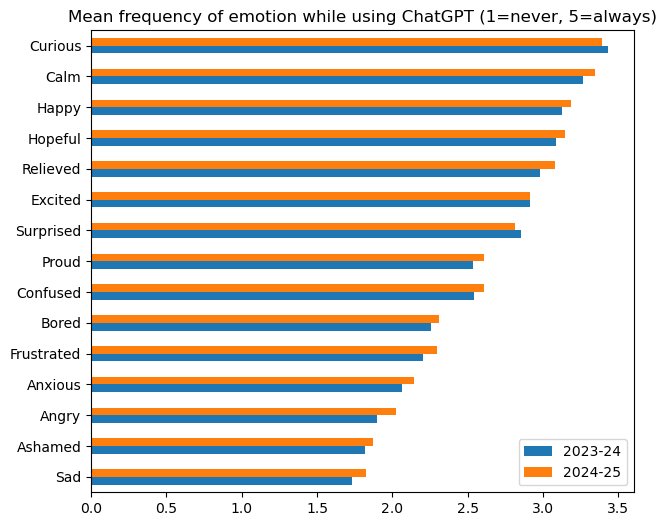

In [ ]:
emo = {'Q32a':'Bored','Q32b':'Hopeful','Q32c':'Sad','Q32d':'Ashamed','Q32e':'Calm','Q32f':'Angry','Q32g':'Relieved','Q32h':'Happy','Q32i':'Proud',
       'Q32j':'Anxious','Q32k':'Surprised','Q32l':'Curious','Q32m':'Excited','Q32n':'Confused','Q32o':'Frustrated'}
e = pd.DataFrame({w: d[list(emo)].mean() for w, d in [('2023-24', raw1), ('2024-25', raw2)]}).rename(index=emo).sort_values('2024-25')
print(e.round(2)); e.plot.barh(figsize=(7,6), title='Mean frequency of emotion while using ChatGPT (1=never, 5=always)'); plt.show()

3. Which gender uses it the most

In [7]:
fld = {1:'Arts & Humanities',2:'Social Sciences',3:'Applied Sciences',4:'Natural & Life Sci.'}
gen = {1:'Male',2:'Female'}
print(raw2.groupby(raw2['Q10'].map(fld))['Q15'].agg(['mean','count']).round(2).sort_values('mean'))
print(raw2[raw2['Q2'].isin([1,2])].groupby(raw2['Q2'].map(gen))['Q15'].agg(['mean','count']).round(2))
print('\nCoding use (Q18l, % often/always) by field:')
print(((raw2['Q18l']>=4).groupby(raw2['Q10'].map(fld)).mean()*100).round(1))

                     mean  count
Q10                             
Arts & Humanities    2.53   1714
Natural & Life Sci.  2.73   2148
Social Sciences      2.73   8446
Applied Sciences     2.92   7021
        mean  count
Q2                 
Female  2.71  11753
Male    2.89   7570

Coding use (Q18l, % often/always) by field:
Q10
Applied Sciences       25.4
Arts & Humanities       8.3
Natural & Life Sci.    15.0
Social Sciences        12.3
Name: Q18l, dtype: float64


4. Users use it more intensely now

In [8]:
for n, d in [('2023-24', raw1), ('2024-25', raw2)]:
    print(n, 'mean Q15 =', round(d['Q15'].mean(), 2))
    print((d['Q15'].value_counts(normalize=True).sort_index()*100).round(1).rename({1:'Rarely',2:'Occasionally',3:'Moderately',4:'Considerably',5:'Extensively'}).to_dict())

2023-24 mean Q15 = 2.48
{'Rarely': 21.2, 'Occasionally': 32.0, 'Moderately': 28.8, 'Considerably': 13.7, 'Extensively': 4.4}
2024-25 mean Q15 = 2.78
{'Rarely': 14.7, 'Occasionally': 27.1, 'Moderately': 31.1, 'Considerably': 19.9, 'Extensively': 7.2}


5. Emerging LLMs

Claude                4.7
Perplexity            7.0
Other                 9.4
Microsoft Copilot    19.1
Google Gemini        25.2
ChatGPT              91.1
dtype: float64


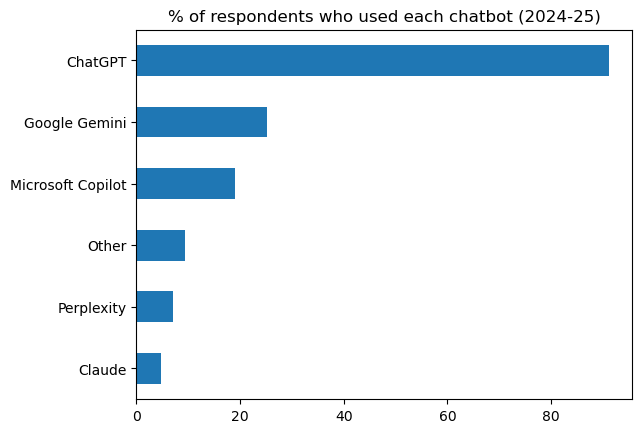


Top free-text answers to "Other":
Q13f_text
deepseek          147
meta ai            50
poe                46
ninguno            25
kimi               20
meta               20
github copilot     19
deepl              18
Name: count, dtype: int64


In [9]:
names = {'Q13a':'ChatGPT','Q13b':'Microsoft Copilot','Q13c':'Google Gemini','Q13d':'Perplexity','Q13e':'Claude','Q13f':'Other'}
answered = raw2[list(names)].notna().all(axis=1)
share = (raw2.loc[answered, list(names)].mean()*100).rename(index=names).sort_values()
print(share.round(1))
share.plot.barh(title='% of respondents who used each chatbot (2024-25)'); plt.show()
print('\nTop free-text answers to "Other":'); print(raw2['Q13f_text'].str.strip().str.lower().value_counts().head(8))

Potential data issues

1. Impossible ages

In [11]:
for n, d in [('2023-24', raw1), ('2024-25', raw2)]:
    raw = d['Q3']
    num = pd.to_numeric(raw, errors='coerce')
    print(f'--- {n}: stored dtype = {raw.dtype}')
    print('non-numeric text values:', raw[num.isna() & raw.notna()].tolist())
    print('birth years entered as age (>=1900):', int((num>=1900).sum()), '| values e.g.', num[num>=1900].head(6).tolist())
    print('age == 100 (the survey max, likely a default/joke):', int((num==100).sum()))
    print('age 80-100:', int(num.between(80,100).sum()), '| under 18 (below the consent minimum):', int((num<18).sum()))
    print('under-18 values:', num[num<18].value_counts().to_dict())

--- 2023-24: stored dtype = float64
non-numeric text values: []
birth years entered as age (>=1900): 49 | values e.g. [2002.0, 2003.0, 1998.0, 2003.0, 2006.0, 2001.0]
age == 100 (the survey max, likely a default/joke): 6
age 80-100: 11 | under 18 (below the consent minimum): 35
under-18 values: {17.0: 26, 15.0: 4, 16.0: 2, 2.0: 1, 14.0: 1, 10.0: 1}
--- 2024-25: stored dtype = object
non-numeric text values: ['19 سنة', '20Years']
birth years entered as age (>=1900): 2 | values e.g. [2004.0, 2005.0]
age == 100 (the survey max, likely a default/joke): 7
age 80-100: 16 | under 18 (below the consent minimum): 0
under-18 values: {}


2. Duplicates

In [16]:
for n, d in [('2023-24', raw1), ('2024-25', raw2)]:
    base = d.drop(columns=['wave','used'], errors='ignore')
    dups = base.duplicated(keep=False)
    print(f'{n}: {int(base.duplicated().sum())} exact duplicate rows ({base.duplicated().mean()*100:.2f}%), involving {int(dups.sum())} rows in total')
# Are the duplicates mostly near-empty rows?  (If so they are 'blank' submissions rather than double submissions.)
#base = raw2.drop(columns=['wave','used'])
d = base[base.duplicated(keep=False)]
print('\n2024-25: share of duplicated rows that answered <60 columns:', round((d.notna().sum(axis=1) < 60).mean()*100,1), '%')
print('Non-empty exact duplicates (genuine double submissions):', int(base.dropna(thresh=60).duplicated().sum()))
print('Duplicates by language source (2024-25):'); print(d['source'].value_counts())

2023-24: 30 exact duplicate rows (0.13%), involving 42 rows in total
2024-25: 127 exact duplicate rows (0.55%), involving 145 rows in total

2024-25: share of duplicated rows that answered <60 columns: 98.6 %
Non-empty exact duplicates (genuine double submissions): 1
Duplicates by language source (2024-25):
source
IT    98
EN    32
AR     9
ES     4
TR     2
Name: count, dtype: int64


3.Missing data

Average % missing per survey section:
                                     2023-24  2024-25
Section 1 demographics (Q6-Q12)          2.2      2.5
Section 2 usage (Q14-Q17)               31.4     14.7
Section 3 capabilities (Q19)            34.2     18.1
Section 8 labour (Q30)                  46.1     31.1
Section 9 emotions (Q32)                46.4     31.5
Section 10 study/personal (Q33-Q39)     23.4     24.5


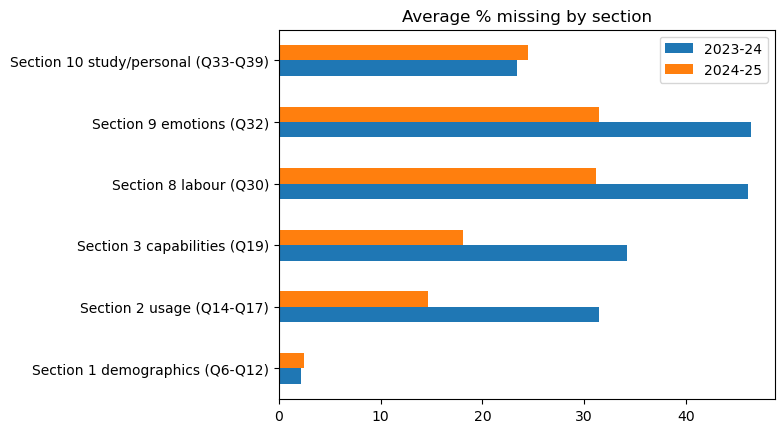


2023-24: Q13=Yes but Q18a blank: 91 of 16010
2023-24: Q13=No  but Q18a answered: 2
2024-25: ticked ChatGPT (Q13a=1) but Q14 blank: 101
2024-25: did NOT tick ChatGPT but Q14 answered: 2
Q13 itself missing: 2023-24 = 804 | 2024-25 = 1351


In [15]:
sec = {'Section 1 demographics (Q6-Q12)':[f'Q{i}' for i in range(6,13)],
       'Section 2 usage (Q14-Q17)':['Q14','Q15','Q16','Q17'],
       'Section 3 capabilities (Q19)':[c for c in raw1.columns if c.startswith('Q19')],
       'Section 8 labour (Q30)':[c for c in raw1.columns if c.startswith('Q30') and len(c)==4],
       'Section 9 emotions (Q32)':[c for c in raw1.columns if c.startswith('Q32') and len(c)==4],
       'Section 10 study/personal (Q33-Q39)':['Q33','Q34','Q36','Q37','Q38','Q39']}
m = pd.DataFrame({w: {k: d[v].isna().mean().mean()*100 for k, v in sec.items()} for w, d in [('2023-24', raw1), ('2024-25', raw2)]})
print('Average % missing per survey section:'); print(m.round(1))
m.plot.barh(title='Average % missing by section'); plt.show()

# Skip-logic leaks: users who say they use ChatGPT but skipped the usage block, and vice-versa
print('\n2023-24: Q13=Yes but Q18a blank:', int(((raw1.Q13==1)&raw1.Q18a.isna()).sum()), 'of', int((raw1.Q13==1).sum()))
print('2023-24: Q13=No  but Q18a answered:', int(((raw1.Q13==2)&raw1.Q18a.notna()).sum()))
print('2024-25: ticked ChatGPT (Q13a=1) but Q14 blank:', int(((raw2.Q13a==1)&raw2.Q14.isna()).sum()))
print('2024-25: did NOT tick ChatGPT but Q14 answered:', int(((raw2.Q13a!=1)&raw2.Q14.notna()).sum()))
print('Q13 itself missing: 2023-24 =', int(raw1.Q13.isna().sum()), '| 2024-25 =', int(raw2.Q13a.isna().sum()))